In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os

import pandas as pd
import xarray as xr
from dotenv import find_dotenv, load_dotenv

from datetime import datetime, UTC

from utils import analysis_utils, isku_utils, plotting_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'utils.isku_utils' from '/home/emily_zuetell/projects/poreallas/utils/isku_utils.py'>

In [2]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

# Define Forecast
EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]

In [3]:
RUN_MONTH = "2026-10"
N_LEADS = 6

_months = pd.period_range(pd.Period(RUN_MONTH, "M"), periods=N_LEADS, freq="M")
FC_MONTHS = [p.month for p in _months]
FC_PERIOD = slice(
    _months[0].start_time.strftime("%Y-%m-%d"),
    _months[-1].end_time.strftime("%Y-%m-%d"),
)

# Baseline period for Impact
BASELINE_PERIOD = slice("1996-01-01", "2025-12-31")


config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=False,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [ ]:
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)

In [4]:
# Projection Effects
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)

In [23]:
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months)

In [13]:
import matplotlib.pyplot as plt
import numpy as np

In [35]:
mmt = effect['/fixed_beta']['mmt'].sel(age_cohort = 'age65plus').mean(dim = 'sample')

In [44]:
### Seasonal Forecast ###
forecast = xr.open_zarr("../data/v2610/v20261006_parsed_forecast.zarr") # Daily ensemble member temp
hindcast = xr.open_zarr("../data/v2610/v20261006_parsed_hindcast.zarr") # Daily ensemble mean temp
# Gridded to Impact Region
forecast_ir = isku_utils.grid_to_ir(forecast, savefile=None)
hindcast_ir = isku_utils.grid_to_ir(hindcast, savefile=None)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfull

In [53]:
da_fc = forecast_ir.mean(dim="number")
merged_fc = xr.merge([da_fc, mmt])
counts_fc = (merged_fc['tas'] > (273+merged_fc['mmt'])).resample(time="1MS").sum().groupby('time.month').mean()

da_hc = hindcast_ir
merged_hc = xr.merge([da_hc, mmt])
counts_hc = (merged_hc['tas'] > (273+merged_hc['mmt'])).resample(time="1MS").sum().groupby('time.month').mean()

counts = counts_fc-counts_hc

In [59]:
da_fc = forecast_ir.mean(dim="number")
merged_fc = xr.merge([da_fc, mmt])
counts_fc = (merged_fc['tas'] - (273+merged_fc['mmt'])).resample(time="1MS").sum().groupby('time.month').mean()

da_hc = hindcast_ir
merged_hc = xr.merge([da_hc, mmt])
counts_hc = (merged_hc['tas'] - (273+merged_hc['mmt'])).resample(time="1MS").sum().groupby('time.month').mean()

counts = counts_fc-counts_hc

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Text(0, 0.5, 'Impact: Monthly Mortality Rate')

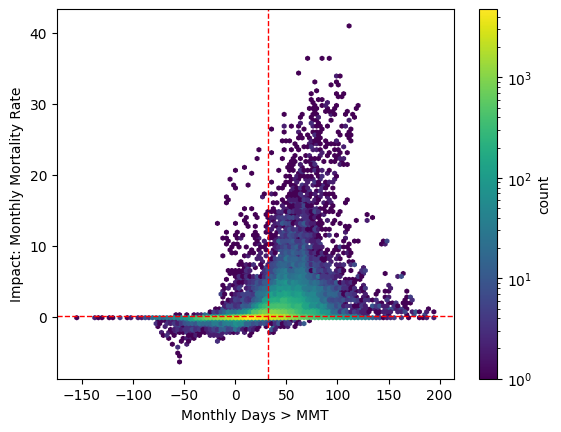

In [60]:
fig, ax = plt.subplots()
a = counts
b = impact.mean(dim = ['number', 'sample'])

ds = xr.merge([a.rename("a"), b.rename("b")], join="inner")

x = ds["a"].values.ravel()
y = ds["b"].values.ravel()

plt.hexbin(ds["a"].values.ravel(), ds["b"].values.ravel(), gridsize=100, bins="log", mincnt=1)
plt.colorbar(label="count")

ax.axvline(np.nanpercentile(x, 50), color="red", linestyle="--", linewidth=1)
ax.axhline(np.nanpercentile(y, 50), color="red", linestyle="--", linewidth=1)

plt.xlabel('Monthly Days > MMT')
plt.ylabel('Impact: Monthly Mortality Rate')

In [ ]:
### Seasonal Forecast ###
forecast = xr.open_zarr("../data/v2610/v20261006_parsed_forecast.zarr") # Daily ensemble member temp
hindcast = xr.open_zarr("../data/v2610/v20261006_parsed_hindcast.zarr") # Daily ensemble mean temp
# Gridded to Impact Region
da = forecast.mean(dim="number")
forecast_ir = isku_utils.grid_to_ir(da, savefile=None)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


In [16]:
config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [17]:
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months)

(0.0, 40.0)

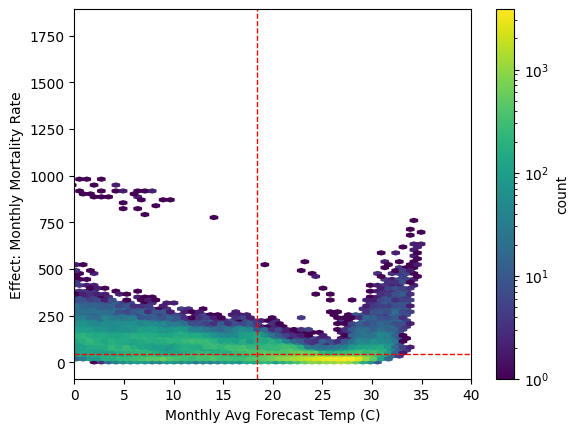

In [19]:
fig, ax = plt.subplots()
a = forecast_ir['tas'].groupby('time.month').mean()-273.15
#b = impact.mean(dim = ['number', 'sample'])
b = effect['/forecast']['effect'].chunk({dim: -1 for dim in config.dims}).chunk({'region': 'auto'}).sel(age_cohort = 'age65plus').groupby('time.month').sum().mean(dim = ['number', 'sample'])

ds = xr.merge([a.rename("a"), b.rename("b")], join="inner")

x = ds["a"].values.ravel()
y = ds["b"].values.ravel()

hb = ax.hexbin(x, y, gridsize=100, bins="log", mincnt=1)

ax.axvline(np.nanpercentile(x, 50), color="red", linestyle="--", linewidth=1)
ax.axhline(np.nanpercentile(y, 50), color="red", linestyle="--", linewidth=1)

fig.colorbar(hb, ax=ax, label="count")
ax.set_xlabel('Monthly Avg Forecast Temp (C)')
ax.set_ylabel('Effect: Monthly Mortality Rate')
ax.set_xlim([0,40])

In [23]:
### Seasonal Forecast ###
forecast = xr.open_zarr("../data/v2610/v20261006_parsed_forecast.zarr") # Daily ensemble member temp
hindcast = xr.open_zarr("../data/v2610/v20261006_parsed_hindcast.zarr") # Daily ensemble mean temp
# Monthly avg temp
forecast = forecast.groupby('time.month').mean().sel(month = config.months)
hindcast = hindcast.groupby('time.month').mean()
#Monthly anomaly relative to 1996-2025 climatological baseline
fc_anomaly = forecast["tas"] - hindcast["tas"]
fc_anom_ir = isku_utils.grid_to_ir(fc_anomaly.mean(dim = 'number'), savefile=None)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


(-5.0, 5.0)

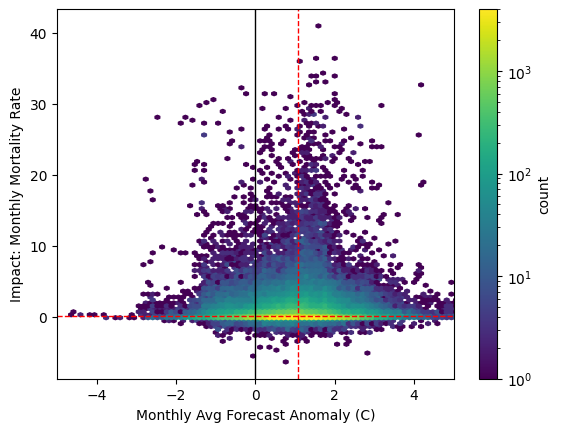

In [27]:
fig, ax = plt.subplots()
a = fc_anom_ir
b = impact.mean(dim = ['number', 'sample'])

ds = xr.merge([a.rename("a"), b.rename("b")], join="inner")

x = ds["a"].values.ravel()
y = ds["b"].values.ravel()

hb = ax.hexbin(x, y, gridsize=100, bins="log", mincnt=1)

ax.axvline(np.nanpercentile(x, 50), color="red", linestyle="--", linewidth=1)
ax.axhline(np.nanpercentile(y, 50), color="red", linestyle="--", linewidth=1)

ax.axvline(0, color="black", linewidth=1)

fig.colorbar(hb, ax=ax, label="count")
#ax.set_xlabel('Monthly Avg Forecast Temp (C)')
#ax.set_ylabel('Effect: Monthly Mortality Rate')
ax.set_xlabel('Monthly Avg Forecast Anomaly (C)')
ax.set_ylabel('Impact: Monthly Mortality Rate')
ax.set_xlim([-5,5])